## Loan Default Risk Prediction and Financial Risk Analytics Using Machine Learning

### 1. Problem Statement

Financial institutions face significant challenges in assessing the creditworthiness of loan applicants and identifying potential loan defaults. Inaccurate risk assessments can result in financial losses, inefficient lending decisions, and increased operational risks.

This project aims to develop a machine learning-based loan default prediction system using historical lending data. The system will analyze borrower characteristics, financial indicators, and loan-related attributes to identify patterns associated with default risk.

### 2. Project Objectives

1. Collect and explore a real-world loan dataset.
2. Clean and preprocess data to improve analytical reliability.
3. Identify significant financial and borrower-related risk indicators.
4. Perform exploratory data analysis using statistical techniques and visualizations.
5. Develop and compare multiple machine learning classification models.
6. Evaluate model performance using appropriate classification metrics.
7. Interpret predictive results and generate business recommendations.
8. Prepare a comprehensive capstone report and presentation.

### 3. Project Scope

The project focuses on historical loan data, exploratory analysis, feature engineering, supervised machine learning, model evaluation, and financial risk interpretation.

The system is intended as an educational decision-support prototype rather than an automated loan approval system.

### 4. Expected Outcomes

- A cleaned and structured loan dataset.
- Statistical insights into historical loan default patterns.
- Visualizations showing relationships between borrower characteristics and default outcomes.
- Trained and evaluated classification models.
- A comparison of model performance.
- Recommendations for improving financial risk monitoring.
- A complete capstone notebook, report, and presentation.

In [2]:
pip install pandas numpy matplotlib seaborn scikit-learn joblib openpyxl jupyter ipykernel

Defaulting to user installation because normal site-packages is not writeable
  Using cached jupyter-1.1.1-py2.py3-none-any.whl.metadata (2.0 kB)
  Using cached notebook-7.6.3-py3-none-any.whl.metadata (10 kB)
  Using cached jupyter_console-6.6.3-py3-none-any.whl.metadata (5.8 kB)
  Using cached nbconvert-7.17.2-py3-none-any.whl.metadata (8.4 kB)
  Using cached ipywidgets-8.1.9-py3-none-any.whl.metadata (2.4 kB)
  Using cached jupyterlab-4.6.4-py3-none-any.whl.metadata (16 kB)
  Using cached widgetsnbextension-4.0.16-py3-none-any.whl.metadata (1.6 kB)
  Using cached jupyterlab_widgets-3.0.17-py3-none-any.whl.metadata (20 kB)
  Using cached async_lru-2.4.0-py3-none-any.whl.metadata (10 kB)
  Using cached httpx-0.28.1-py3-none-any.whl.metadata (7.1 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached jupyter_builder-1.2.4-py3-none-any.whl.metadata (7.8 kB)
  Using cached jupyter_lsp-2.3.1-py3-none-any.whl.metadata (1.8 kB)
  Using cached jupyter_server-2.21.1

ERROR: Could not install packages due to an OSError: [Errno 2] No such file or directory: 'C:\\Users\\NISHA\\AppData\\Local\\Packages\\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\\LocalCache\\local-packages\\Python312\\site-packages\\jupyterlab\\galata\\@jupyterlab\\galata-extension\\static\\vendors-node_modules_fontsource-variable_noto-sans-sc_index_css.386da7677f8b1f52.js'
HINT: This error might have occurred since this system does not have Windows Long Path support enabled. You can find information on how to enable this at https://pip.pypa.io/warnings/enable-long-paths


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\NISHA\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

sns.set_theme(style="whitegrid")

Path("data").mkdir(exist_ok=True)
Path("visualizations").mkdir(exist_ok=True)
Path("models").mkdir(exist_ok=True)
Path("reports").mkdir(exist_ok=True)

print("Capstone environment initialized successfully!")

Capstone environment initialized successfully!


In [4]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/statlog/german/german.data"
)

columns = [
    "Checking_Status", "Duration", "Credit_History",
    "Purpose", "Credit_Amount", "Savings_Status",
    "Employment", "Installment_Rate", "Personal_Status",
    "Other_Debtors", "Residence_Since", "Property",
    "Age", "Other_Installment_Plans", "Housing",
    "Existing_Credits", "Job", "Dependents",
    "Telephone", "Foreign_Worker", "Credit_Risk"
]

df = pd.read_csv(
    url,
    sep=r"\s+",
    header=None,
    names=columns
)

# UCI coding: 1 = good credit risk, 2 = bad credit risk
df["Credit_Risk"] = df["Credit_Risk"].map({1: 0, 2: 1})

df.to_csv("data/german_credit.csv", index=False)

print("Dataset Shape:", df.shape)
print("\nCredit Risk Distribution:")
print(df["Credit_Risk"].value_counts())

display(df.head())

Dataset Shape: (1000, 21)

Credit Risk Distribution:
Credit_Risk
0    700
1    300
Name: count, dtype: int64


,Checking_Status,Duration,Credit_History,Purpose,Credit_Amount,Savings_Status,Employment,Installment_Rate,Personal_Status,Other_Debtors,...,Property,Age,Other_Installment_Plans,Housing,Existing_Credits,Job,Dependents,Telephone,Foreign_Worker,Credit_Risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


## Step 1: Data Exploration and Preprocessing

### Step 1.1: Exploring the dataset
Dataset Exploration: This stage examines the structure, completeness, data types, and statistical properties of the German Credit dataset. The objective is to identify data quality issues and understand the variables before applying machine learning techniques.

In [5]:
# Basic dataset exploration

print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nFirst 10 Records:")
display(df.head(10))

print("\nStatistical Summary:")
display(df.describe(include="all").T)

print("\nColumn Data Types:")
print(df.dtypes)

Dataset Shape: (1000, 21)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Checking_Status          1000 non-null   str  
 1   Duration                 1000 non-null   int64
 2   Credit_History           1000 non-null   str  
 3   Purpose                  1000 non-null   str  
 4   Credit_Amount            1000 non-null   int64
 5   Savings_Status           1000 non-null   str  
 6   Employment               1000 non-null   str  
 7   Installment_Rate         1000 non-null   int64
 8   Personal_Status          1000 non-null   str  
 9   Other_Debtors            1000 non-null   str  
 10  Residence_Since          1000 non-null   int64
 11  Property                 1000 non-null   str  
 12  Age                      1000 non-null   int64
 13  Other_Installment_Plans  1000 non-null   str  
 14  Housing             

,Checking_Status,Duration,Credit_History,Purpose,Credit_Amount,Savings_Status,Employment,Installment_Rate,Personal_Status,Other_Debtors,...,Property,Age,Other_Installment_Plans,Housing,Existing_Credits,Job,Dependents,Telephone,Foreign_Worker,Credit_Risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1
5,A14,36,A32,A46,9055,A65,A73,2,A93,A101,...,A124,35,A143,A153,1,A172,2,A192,A201,0
6,A14,24,A32,A42,2835,A63,A75,3,A93,A101,...,A122,53,A143,A152,1,A173,1,A191,A201,0
7,A12,36,A32,A41,6948,A61,A73,2,A93,A101,...,A123,35,A143,A151,1,A174,1,A192,A201,0
8,A14,12,A32,A43,3059,A64,A74,2,A91,A101,...,A121,61,A143,A152,1,A172,1,A191,A201,0
9,A12,30,A34,A40,5234,A61,A71,4,A94,A101,...,A123,28,A143,A152,2,A174,1,A191,A201,1



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Checking_Status,1000,4,A14,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Credit_History,1000,5,A32,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Purpose,1000,10,A43,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit_Amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Savings_Status,1000,5,A61,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Employment,1000,5,A73,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installment_Rate,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
Personal_Status,1000,4,A93,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Other_Debtors,1000,3,A101,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Column Data Types:
Checking_Status              str
Duration                   int64
Credit_History               str
Purpose                      str
Credit_Amount              int64
Savings_Status               str
Employment                   str
Installment_Rate           int64
Personal_Status              str
Other_Debtors                str
Residence_Since            int64
Property                     str
Age                        int64
Other_Installment_Plans      str
Housing                      str
Existing_Credits           int64
Job                          str
Dependents                 int64
Telephone                    str
Foreign_Worker               str
Credit_Risk                int64
dtype: object


### Step 1.2: Checking data quality

In [6]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check target variable
print("\nCredit Risk Distribution:")
print(df["Credit_Risk"].value_counts())

print("\nCredit Risk Percentage:")
print(df["Credit_Risk"].value_counts(normalize=True) * 100)

Missing Values:
Checking_Status            0
Duration                   0
Credit_History             0
Purpose                    0
Credit_Amount              0
Savings_Status             0
Employment                 0
Installment_Rate           0
Personal_Status            0
Other_Debtors              0
Residence_Since            0
Property                   0
Age                        0
Other_Installment_Plans    0
Housing                    0
Existing_Credits           0
Job                        0
Dependents                 0
Telephone                  0
Foreign_Worker             0
Credit_Risk                0
dtype: int64

Duplicate Records: 0

Credit Risk Distribution:
Credit_Risk
0    700
1    300
Name: count, dtype: int64

Credit Risk Percentage:
Credit_Risk
0    70.0
1    30.0
Name: proportion, dtype: float64


### Step 1.3: Exploring numerical variables

In [7]:
numerical_features = [
    "Duration",
    "Credit_Amount",
    "Installment_Rate",
    "Residence_Since",
    "Age",
    "Existing_Credits",
    "Dependents"
]

print("Numerical Feature Summary:")
display(df[numerical_features].describe().T)

print("\nCorrelation Matrix:")
display(df[numerical_features + ["Credit_Risk"]].corr().round(2))

Numerical Feature Summary:


,count,mean,std,min,25%,50%,75%,max
Duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
Credit_Amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Installment_Rate,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
Residence_Since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
Age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
Existing_Credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
Dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0



Correlation Matrix:


,Duration,Credit_Amount,Installment_Rate,Residence_Since,Age,Existing_Credits,Dependents,Credit_Risk
Duration,1.00,0.62,0.07,0.03,-0.04,-0.01,-0.02,0.21
Credit_Amount,0.62,1.00,-0.27,0.03,0.03,0.02,0.02,0.15
Installment_Rate,0.07,-0.27,1.00,0.05,0.06,0.02,-0.07,0.07
Residence_Since,0.03,0.03,0.05,1.00,0.27,0.09,0.04,0.00
Age,-0.04,0.03,0.06,0.27,1.00,0.15,0.12,-0.09
Existing_Credits,-0.01,0.02,0.02,0.09,0.15,1.00,0.11,-0.05
Dependents,-0.02,0.02,-0.07,0.04,0.12,0.11,1.00,-0.00
Credit_Risk,0.21,0.15,0.07,0.00,-0.09,-0.05,-0.00,1.00


### Step 1.4: Feature engineering

In [8]:
# Create a working copy
df_processed = df.copy()

# Approximate credit amount per month of loan duration
df_processed["Credit_Per_Month"] = (
    df_processed["Credit_Amount"] /
    df_processed["Duration"]
)

# Age groups for exploratory analysis
df_processed["Age_Group"] = pd.cut(
    df_processed["Age"],
    bins=[0, 25, 35, 50, 100],
    labels=["18-25", "26-35", "36-50", "Above 50"]
)

# Loan duration groups
df_processed["Duration_Group"] = pd.cut(
    df_processed["Duration"],
    bins=[0, 12, 24, 36, float("inf")],
    labels=[
        "Up to 12 Months",
        "13-24 Months",
        "25-36 Months",
        "Above 36 Months"
    ]
)

print("Feature Engineering Completed!")
print("Updated Dataset Shape:", df_processed.shape)

display(df_processed.head())

Feature Engineering Completed!
Updated Dataset Shape: (1000, 24)


,Checking_Status,Duration,Credit_History,Purpose,Credit_Amount,Savings_Status,Employment,Installment_Rate,Personal_Status,Other_Debtors,...,Housing,Existing_Credits,Job,Dependents,Telephone,Foreign_Worker,Credit_Risk,Credit_Per_Month,Age_Group,Duration_Group
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A152,2,A173,1,A192,A201,0,194.833333,Above 50,Up to 12 Months
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A152,1,A173,1,A191,A201,1,123.979167,18-25,Above 36 Months
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A152,1,A172,2,A191,A201,0,174.666667,36-50,Up to 12 Months
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A153,1,A173,2,A191,A201,0,187.666667,36-50,Above 36 Months
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A153,2,A173,2,A191,A201,1,202.916667,Above 50,13-24 Months


### Step 1.5: Saving the prepared dataset

In [9]:
df_processed.to_csv(
    "data/german_credit_prepared.csv",
    index=False
)

print("Prepared dataset saved successfully!")

Prepared dataset saved successfully!


### Step 1.6: Preparing training and testing data

In [10]:
from sklearn.model_selection import train_test_split

# Exclude target, descriptive groups, and sensitive attributes
excluded_columns = [
    "Credit_Risk",
    "Age",
    "Age_Group",
    "Duration_Group",
    "Personal_Status",
    "Foreign_Worker"
]

X = df_processed.drop(columns=excluded_columns)
y = df_processed["Credit_Risk"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Samples: 800
Testing Samples: 200

Training Class Distribution:
Credit_Risk
0    560
1    240
Name: count, dtype: int64

Testing Class Distribution:
Credit_Risk
0    140
1     60
Name: count, dtype: int64


## Step 2: Exploratory Data Analysis (EDA) & Visualizations
#### Objective: Identify patterns associated with historical credit risk and communicate them through professional visualizations.

### Step 2.1: Configure visualization settings

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pathlib import Path

Path("visualizations").mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11

# Add readable labels for visualizations
eda_df = df_processed.copy()

eda_df["Risk_Label"] = eda_df["Credit_Risk"].map({
    0: "Good Credit Risk",
    1: "Bad Credit Risk"
})

print("EDA environment ready!")

EDA environment ready!


### Step 2.2: Credit risk distribution

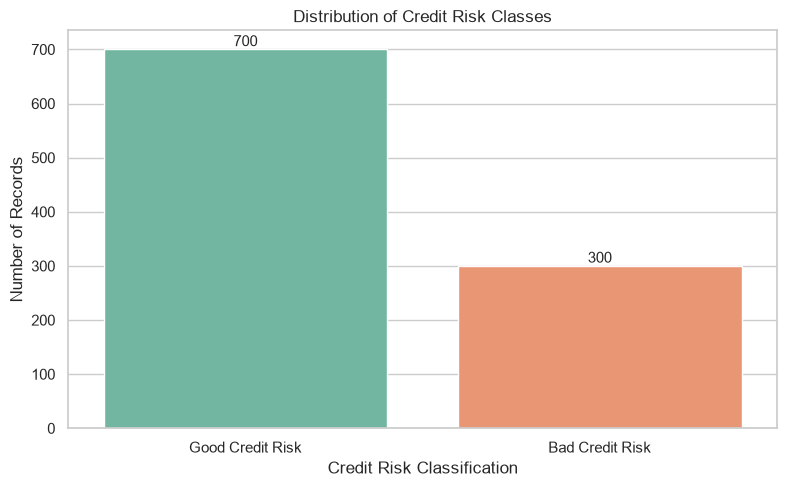

In [12]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=eda_df,
    x="Risk_Label",
    order=["Good Credit Risk", "Bad Credit Risk"],
    hue="Risk_Label",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Distribution of Credit Risk Classes")
plt.xlabel("Credit Risk Classification")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.savefig("visualizations/Credit_Risk_Distribution.png", dpi=300)
plt.show()

### Step 2.3: Credit amount distribution

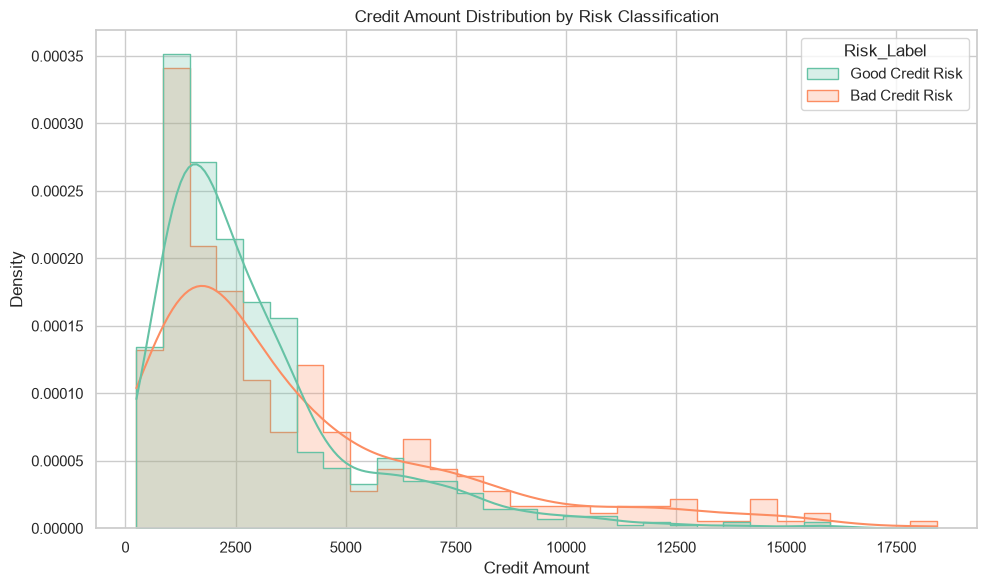

In [13]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=eda_df,
    x="Credit_Amount",
    hue="Risk_Label",
    bins=30,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Credit Amount Distribution by Risk Classification")
plt.xlabel("Credit Amount")
plt.ylabel("Density")

plt.tight_layout()
plt.savefig("visualizations/Credit_Amount_Distribution.png", dpi=300)
plt.show()

### Step 2.4: Loan duration versus credit risk

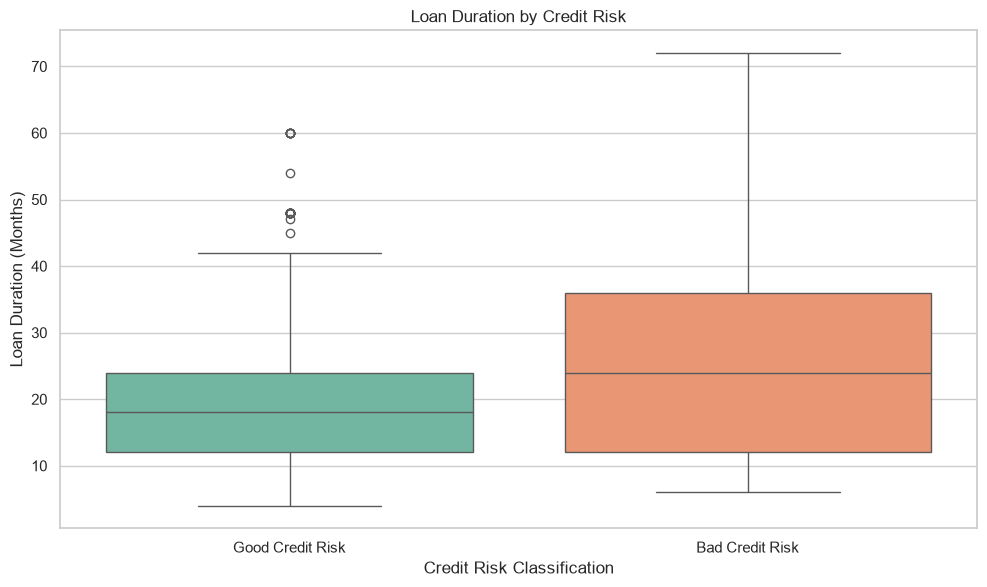

In [14]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=eda_df,
    x="Risk_Label",
    y="Duration",
    hue="Risk_Label",
    palette="Set2",
    legend=False
)

plt.title("Loan Duration by Credit Risk")
plt.xlabel("Credit Risk Classification")
plt.ylabel("Loan Duration (Months)")

plt.tight_layout()
plt.savefig("visualizations/Loan_Duration_Risk.png", dpi=300)
plt.show()

### Step 2.5: Risk percentage by checking account status

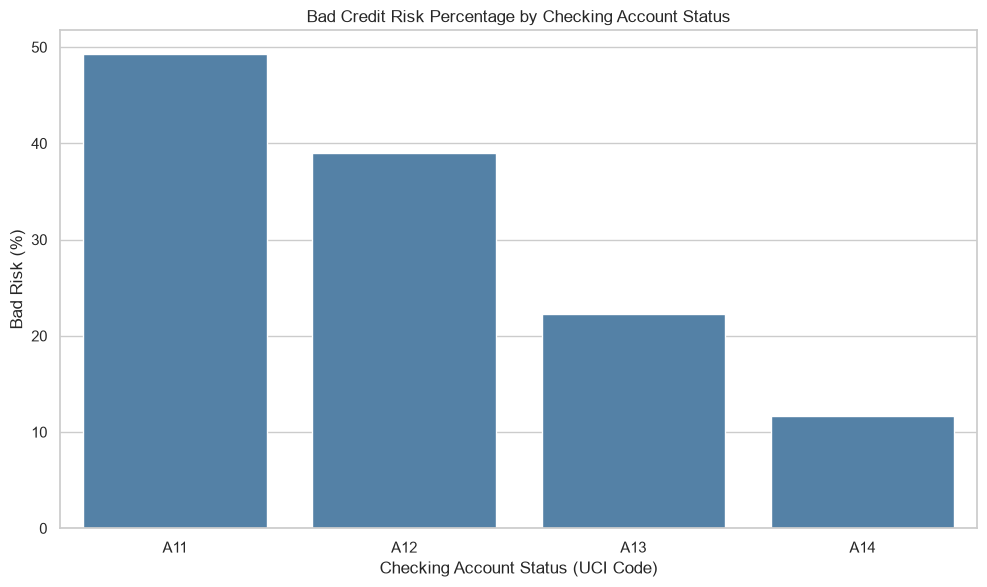

,Checking_Status,mean,count,Bad_Risk_Percentage
0,A11,0.49,274,49.27
1,A12,0.39,269,39.03
2,A13,0.22,63,22.22
3,A14,0.12,394,11.68


In [15]:
checking_risk = (
    eda_df.groupby("Checking_Status")["Credit_Risk"]
    .agg(["mean", "count"])
    .reset_index()
)

checking_risk["Bad_Risk_Percentage"] = checking_risk["mean"] * 100

plt.figure(figsize=(10, 6))

sns.barplot(
    data=checking_risk,
    x="Checking_Status",
    y="Bad_Risk_Percentage",
    color="steelblue"
)

plt.title("Bad Credit Risk Percentage by Checking Account Status")
plt.xlabel("Checking Account Status (UCI Code)")
plt.ylabel("Bad Risk (%)")

plt.tight_layout()
plt.savefig("visualizations/Checking_Status_Risk.png", dpi=300)
plt.show()

display(checking_risk.round(2))

### Step 2.6: Credit risk by loan duration group

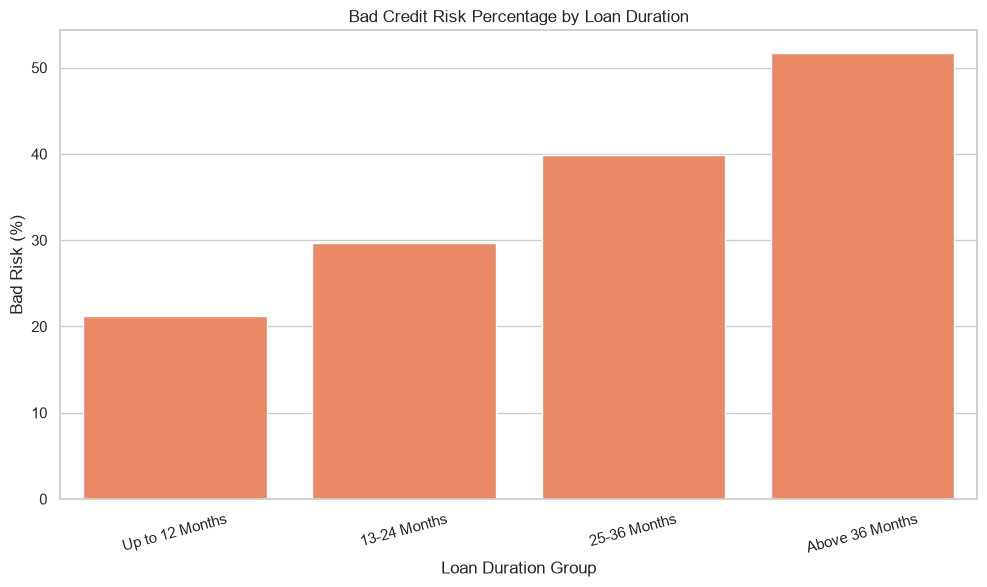

,Duration_Group,Total_Records,Bad_Risk_Rate,Bad_Risk_Percentage
0,Up to 12 Months,359,0.21,21.17
1,13-24 Months,411,0.30,29.68
2,25-36 Months,143,0.40,39.86
3,Above 36 Months,87,0.52,51.72


In [16]:
duration_risk = (
    eda_df.groupby("Duration_Group", observed=True)
    .agg(
        Total_Records=("Credit_Risk", "count"),
        Bad_Risk_Rate=("Credit_Risk", "mean")
    )
    .reset_index()
)

duration_risk["Bad_Risk_Percentage"] = (
    duration_risk["Bad_Risk_Rate"] * 100
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=duration_risk,
    x="Duration_Group",
    y="Bad_Risk_Percentage",
    color="coral"
)

plt.title("Bad Credit Risk Percentage by Loan Duration")
plt.xlabel("Loan Duration Group")
plt.ylabel("Bad Risk (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.savefig("visualizations/Duration_Group_Risk.png", dpi=300)
plt.show()

display(duration_risk.round(2))

### Step 2.7: Credit amount versus loan duration

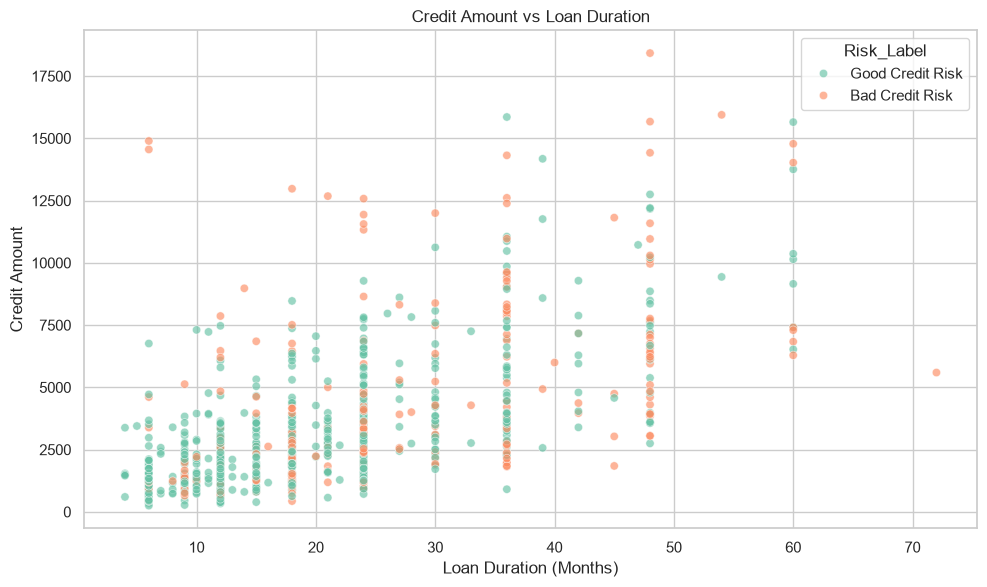

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=eda_df,
    x="Duration",
    y="Credit_Amount",
    hue="Risk_Label",
    alpha=0.65
)

plt.title("Credit Amount vs Loan Duration")
plt.xlabel("Loan Duration (Months)")
plt.ylabel("Credit Amount")

plt.tight_layout()
plt.savefig("visualizations/Credit_Amount_vs_Duration.png", dpi=300)
plt.show()

### Step 2.8: Numerical feature correlation heatmap

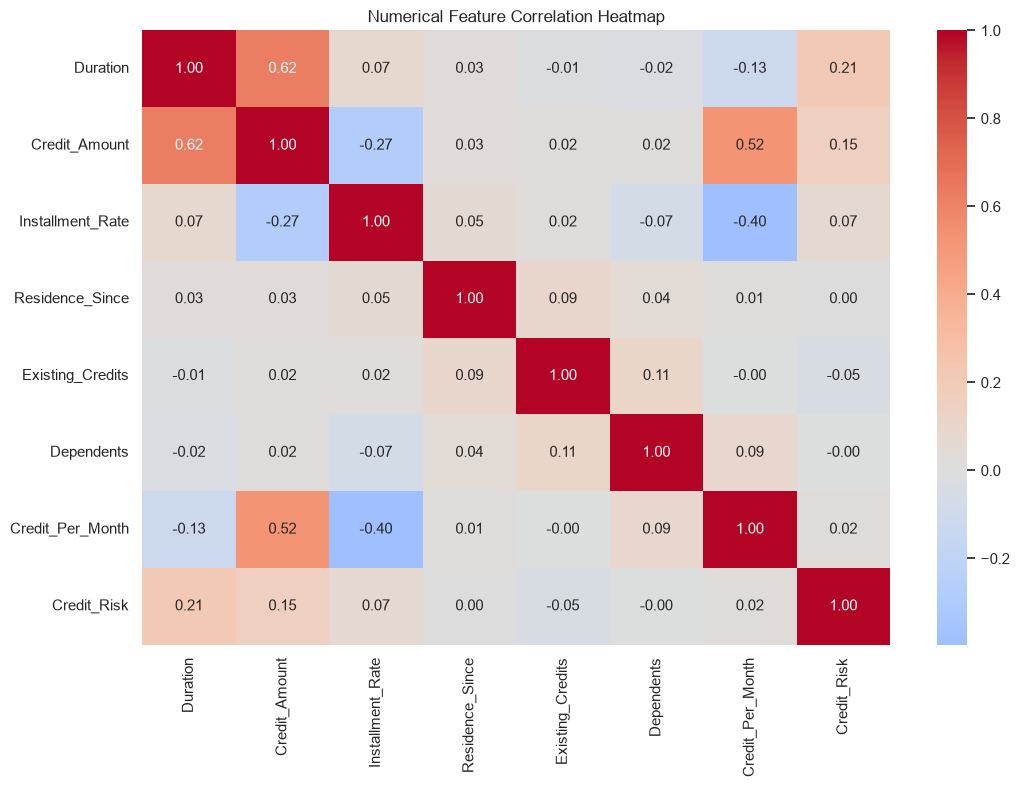

In [18]:
correlation_features = [
    "Duration",
    "Credit_Amount",
    "Installment_Rate",
    "Residence_Since",
    "Existing_Credits",
    "Dependents",
    "Credit_Per_Month",
    "Credit_Risk"
]

correlation_matrix = eda_df[
    correlation_features
].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Numerical Feature Correlation Heatmap")

plt.tight_layout()
plt.savefig("visualizations/Correlation_Heatmap.png", dpi=300)
plt.show()

### Step 2.9: Credit risk by savings account status

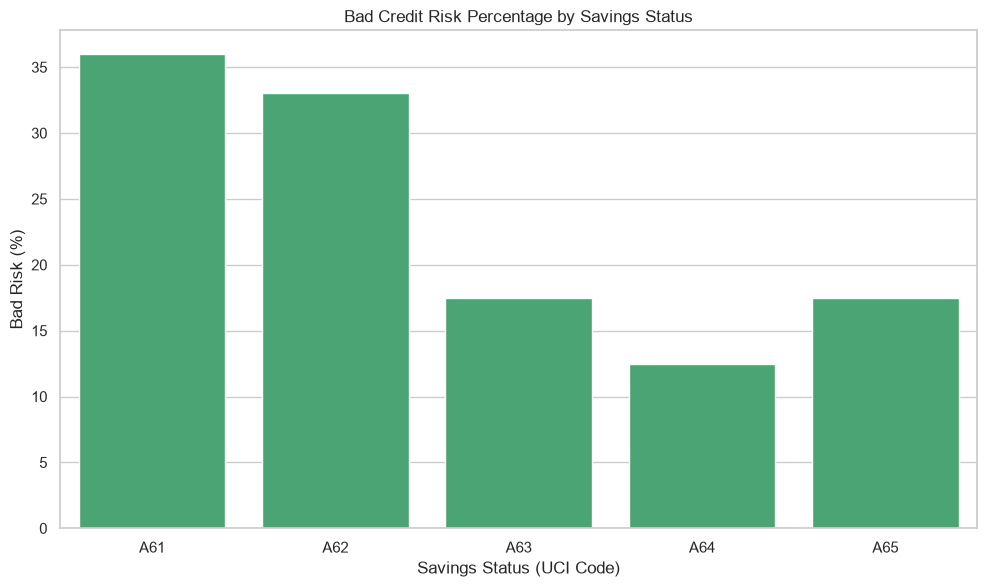

,Savings_Status,mean,count,Bad_Risk_Percentage
0,A61,0.36,603,35.99
1,A62,0.33,103,33.01
2,A63,0.17,63,17.46
3,A64,0.12,48,12.50
4,A65,0.17,183,17.49


In [19]:
savings_risk = (
    eda_df.groupby("Savings_Status")["Credit_Risk"]
    .agg(["mean", "count"])
    .reset_index()
)

savings_risk["Bad_Risk_Percentage"] = savings_risk["mean"] * 100

plt.figure(figsize=(10, 6))

sns.barplot(
    data=savings_risk,
    x="Savings_Status",
    y="Bad_Risk_Percentage",
    color="mediumseagreen"
)

plt.title("Bad Credit Risk Percentage by Savings Status")
plt.xlabel("Savings Status (UCI Code)")
plt.ylabel("Bad Risk (%)")

plt.tight_layout()
plt.savefig("visualizations/Savings_Status_Risk.png", dpi=300)
plt.show()

display(savings_risk.round(2))

### Step 2.10: Save the EDA summary

In [20]:
eda_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Good Credit Risk Records",
        "Bad Credit Risk Records",
        "Bad Credit Risk Percentage",
        "Average Credit Amount",
        "Median Credit Amount",
        "Average Loan Duration"
    ],
    "Value": [
        len(eda_df),
        (eda_df["Credit_Risk"] == 0).sum(),
        (eda_df["Credit_Risk"] == 1).sum(),
        round(eda_df["Credit_Risk"].mean() * 100, 2),
        round(eda_df["Credit_Amount"].mean(), 2),
        round(eda_df["Credit_Amount"].median(), 2),
        round(eda_df["Duration"].mean(), 2)
    ]
})

display(eda_summary)

eda_summary.to_csv(
    "reports/EDA_Summary.csv",
    index=False
)

print("EDA summary saved successfully!")

,Metric,Value
0,Total Records,1000.00
1,Good Credit Risk Records,700.00
2,Bad Credit Risk Records,300.00
3,Bad Credit Risk Percentage,30.00
4,Average Credit Amount,3271.26
5,Median Credit Amount,2319.50
6,Average Loan Duration,20.90


EDA summary saved successfully!


## Step 3: Machine Learning Model Development & Evaluation

### Step 3.1: Preparing the preprocessing pipeline

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Identify feature types
numeric_columns = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:", numeric_columns)
print("\nCategorical Features:", categorical_columns)

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_columns)
    ]
)

print("\nPreprocessing pipeline created successfully!")

Numerical Features: ['Duration', 'Credit_Amount', 'Installment_Rate', 'Residence_Since', 'Existing_Credits', 'Dependents', 'Credit_Per_Month']

Categorical Features: ['Checking_Status', 'Credit_History', 'Purpose', 'Savings_Status', 'Employment', 'Other_Debtors', 'Property', 'Other_Installment_Plans', 'Housing', 'Job', 'Telephone']

Preprocessing pipeline created successfully!


C:\TEMP\ipykernel_5872\2927435393.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


### Step 3.2: Training Logistic Regression
#### Logistic Regression is a supervised classification algorithm that estimates the probability of a binary outcome.

In [22]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

lr_predictions = logistic_model.predict(X_test)
lr_probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression training completed!")

Logistic Regression training completed!


### Step 3.3: Training Random Forest

In [23]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest training completed!")

Random Forest training completed!


### Step 3.4: Evaluating both models

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

def evaluate_model(name, y_true, predictions, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1-Score": f1_score(y_true, predictions),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

results = [
    evaluate_model(
        "Logistic Regression",
        y_test,
        lr_predictions,
        lr_probabilities
    ),
    evaluate_model(
        "Random Forest",
        y_test,
        rf_predictions,
        rf_probabilities
    )
]

results_df = pd.DataFrame(results)

display(results_df.round(4))

results_df.to_csv(
    "reports/Model_Comparison.csv",
    index=False
)

print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, lr_predictions))

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_predictions))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.780,0.6667,0.5333,0.5926,0.7931
1,Random Forest,0.765,0.6102,0.6000,0.6050,0.7851



Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.89      0.85       140
           1       0.67      0.53      0.59        60

    accuracy                           0.78       200
   macro avg       0.74      0.71      0.72       200
weighted avg       0.77      0.78      0.77       200


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.84      0.83       140
           1       0.61      0.60      0.61        60

    accuracy                           0.77       200
   macro avg       0.72      0.72      0.72       200
weighted avg       0.76      0.77      0.76       200



### Step 3.5: Visualizing the model comparison

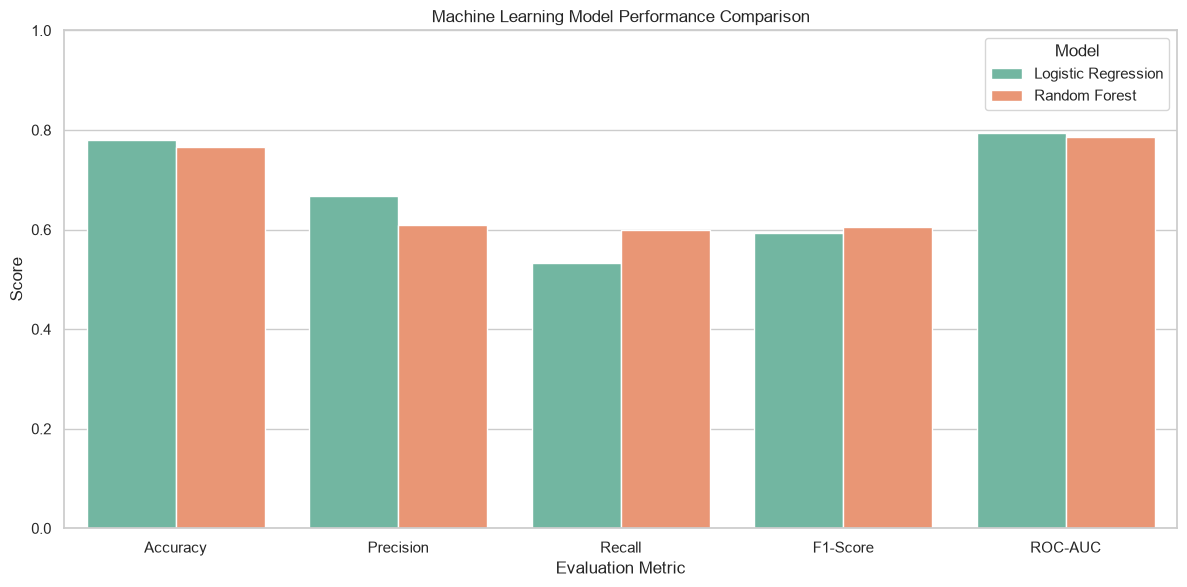

In [25]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

comparison = results_df.melt(
    id_vars="Model",
    value_vars=metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig(
    "visualizations/Model_Comparison.png",
    dpi=300
)
plt.show()

### Step 3.6: Generating confusion matrices
#### A confusion matrix helps identify correct and incorrect classifications, including bad-risk cases missed by each model.

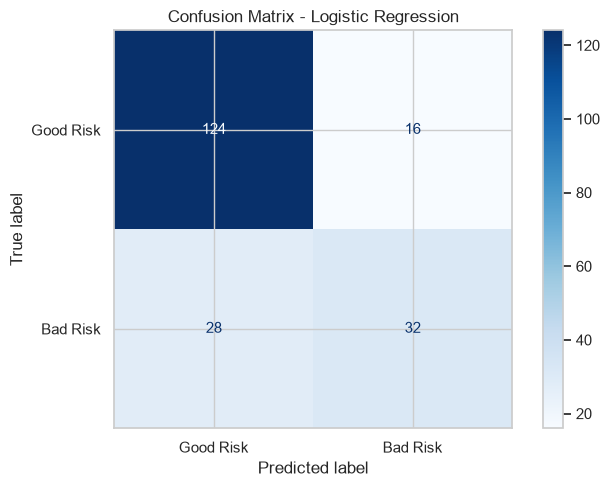

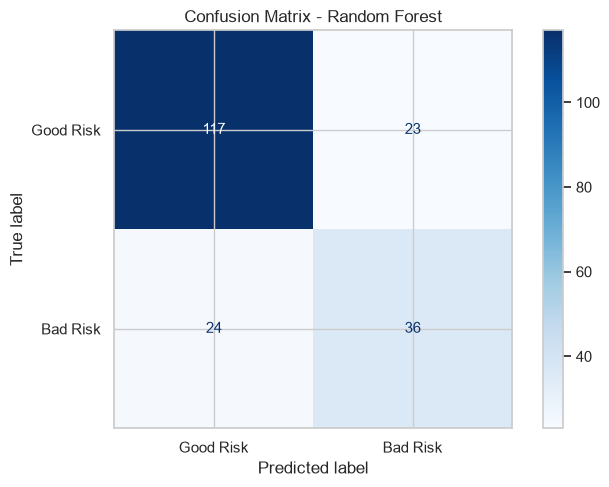

In [26]:
from sklearn.metrics import ConfusionMatrixDisplay

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

for name, model in models.items():

    fig, ax = plt.subplots(figsize=(7, 5))

    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["Good Risk", "Bad Risk"],
        cmap="Blues",
        ax=ax
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()

    filename = name.replace(" ", "_")

    plt.savefig(
        f"visualizations/{filename}_Confusion_Matrix.png",
        dpi=300
    )

    plt.show()

### Step 3.7: Plotting ROC curves
#### The ROC curve illustrates the trade-off between the true positive rate and false positive rate across different classification thresholds.

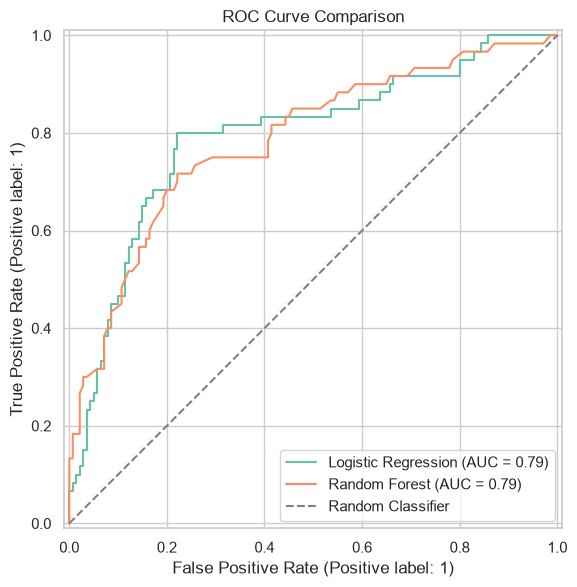

In [27]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(9, 6))

for name, model in models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curve Comparison")
plt.legend()
plt.tight_layout()

plt.savefig(
    "visualizations/ROC_Curve_Comparison.png",
    dpi=300
)

plt.show()

### Step 3.8: Identify important features

,Feature,Importance
0,Checking_Status,0.1309
3,Purpose,0.0166
5,Savings_Status,0.0126
2,Credit_History,0.0106
8,Other_Debtors,0.0106
11,Other_Installment_Plans,0.0068
17,Credit_Per_Month,0.0065
4,Credit_Amount,0.0049
14,Job,0.0046
9,Residence_Since,0.0043


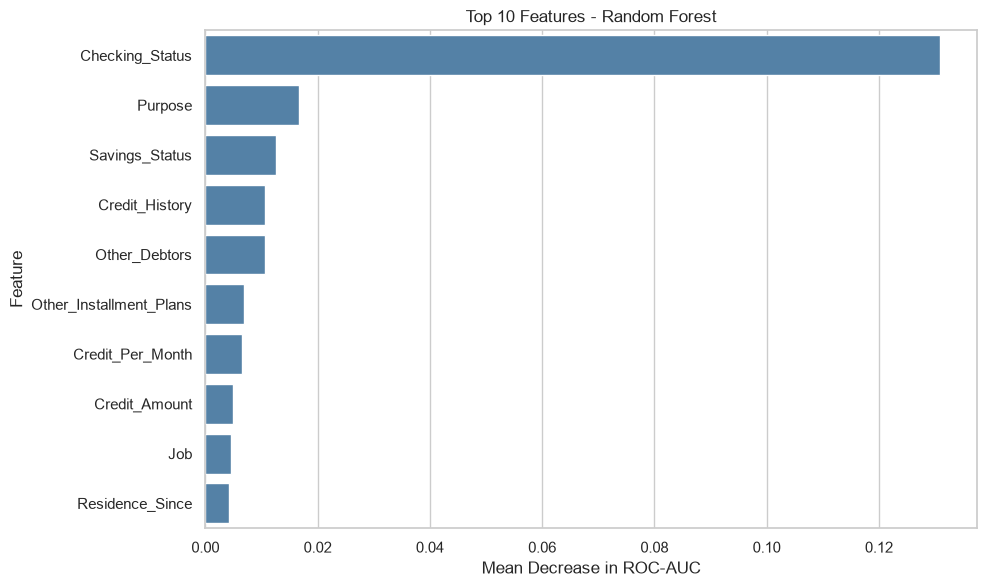

In [28]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    random_forest_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=10,
    random_state=42
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance.importances_mean
}).sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(10).round(4))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title("Top 10 Features - Random Forest")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Feature")

plt.tight_layout()
plt.savefig(
    "visualizations/Feature_Importance.png",
    dpi=300
)
plt.show()

### Step 3.9: Selecting and saving the best model

In [29]:
import joblib

best_model_name = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).iloc[0]["Model"]

best_model = models[best_model_name]

joblib.dump(
    best_model,
    "models/best_credit_risk_model.pkl"
)

print("Best Model:", best_model_name)
print("Model saved successfully!")

Best Model: Logistic Regression
Model saved successfully!


## Step 4: Cross-Validation and Final Model Selection

### Step 4.1: Perform 5-fold Stratified Cross-Validation

In [30]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

cv_results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1-Score": scores["test_F1"].mean(),
        "ROC-AUC": scores["test_ROC_AUC"].mean(),
        "ROC-AUC Std": scores["test_ROC_AUC"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

cv_results_df.to_csv(
    "reports/Cross_Validation_Results.csv",
    index=False
)

print("Cross-validation completed successfully!")

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,ROC-AUC Std
0,Logistic Regression,0.7425,0.5975,0.4417,0.5058,0.7625,0.0586
1,Random Forest,0.7513,0.5844,0.5833,0.5818,0.7923,0.0406


Cross-validation completed successfully!


### Step 4.2: Visualize Cross-Validation Performance

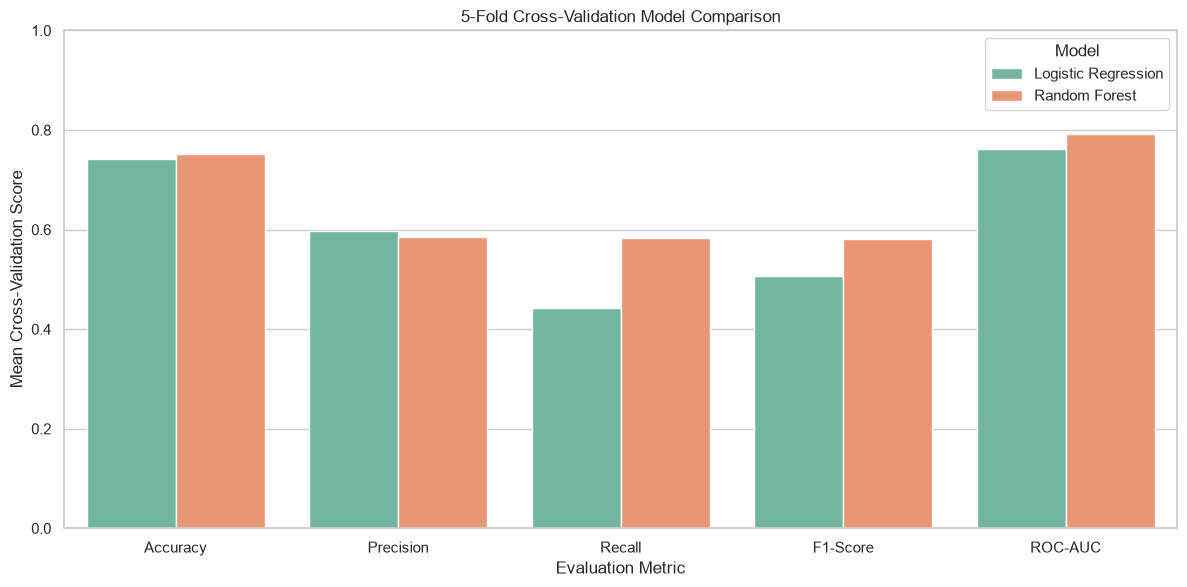

In [31]:
cv_plot = cv_results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=cv_plot,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("5-Fold Cross-Validation Model Comparison")
plt.ylabel("Mean Cross-Validation Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)

plt.tight_layout()

plt.savefig(
    "visualizations/Cross_Validation_Comparison.png",
    dpi=300
)

plt.show()

### Step 4.3: Selecting the Final Model Using Cross-Validation

In [32]:
import joblib

final_model_name = cv_results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).iloc[0]["Model"]

final_model = models[final_model_name]

# Fit the selected pipeline on all training data
final_model.fit(X_train, y_train)

# Evaluate on the held-out test set
final_predictions = final_model.predict(X_test)
final_probabilities = final_model.predict_proba(X_test)[:, 1]

final_metrics = evaluate_model(
    final_model_name,
    y_test,
    final_predictions,
    final_probabilities
)

print("Final Selected Model:", final_model_name)
print("\nFinal Test Results:")
display(pd.DataFrame([final_metrics]).round(4))

# Save the final model
joblib.dump(
    final_model,
    "models/final_credit_risk_model.pkl"
)

print("Final model saved successfully!")

Final Selected Model: Random Forest

Final Test Results:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.765,0.6102,0.6,0.605,0.7851


Final model saved successfully!


## Step 5: Business Insights and Recommendations

### 5.1 Key Business Insights

**Insight 1: Historical Credit Risk Can Be Analyzed Using Machine Learning**

The machine learning analysis demonstrated that historical borrower and loan-related information contains patterns associated with credit-risk classifications. The Random Forest model achieved an accuracy of 76.50% and an ROC-AUC score of 0.7851 on the test dataset.

These findings suggest that machine learning can support exploratory credit-risk analysis by identifying relationships across multiple financial attributes. However, predictive performance alone does not establish suitability for real-world lending decisions.

**Insight 2: Checking Account Status Is an Important Predictive Feature**

Permutation importance analysis identified Checking_Status as the most influential feature for the Random Forest classifier, with an average ROC-AUC decrease of 0.1309 when its values were randomly shuffled.

Other relevant features included Purpose (0.0166), Savings_Status (0.0126), Credit_History (0.0106), and Other_Debtors (0.0106).

The substantial difference between Checking_Status and the remaining features indicates that the model relies heavily on information represented by checking account categories. This relationship warrants further investigation to understand its stability and possible implications for model fairness.

**Insight 3: Random Forest Provides Better Detection of Bad-Risk Cases**

The Random Forest classifier achieved a recall of 60.00%, compared with 53.33% for Logistic Regression on the test dataset.

Random Forest correctly identified 36 of the 60 bad-risk records, while Logistic Regression identified 32. This improvement suggests that Random Forest may be more suitable for research scenarios where identifying historically bad-risk cases is a priority.

Nevertheless, Random Forest still failed to identify 24 bad-risk records, demonstrating that its sensitivity requires improvement.

**Insight 4: Accuracy Alone Is Insufficient for Risk Assessment**

Although Logistic Regression achieved higher test accuracy (78.00%) than Random Forest (76.50%), Random Forest performed better in recall and F1-score.

This difference highlights the importance of considering multiple performance indicators when evaluating classification systems. In credit-risk analysis, false negatives and false positives may carry different consequences, making recall, precision, F1-score, and ROC-AUC important alongside accuracy.

**Insight 5: Cross-Validation Supports Random Forest Selection**

Five-fold stratified cross-validation produced a mean ROC-AUC of 0.7923 for Random Forest, compared with 0.7625 for Logistic Regression.

Random Forest also achieved a higher mean F1-score (0.5818 versus 0.5058) and higher mean recall (0.5833 versus 0.4417).

These findings supported selecting Random Forest as the final experimental model using the cross-validation results rather than the initial test-set accuracy ranking.

### 5.2 Actionable Business Recommendations

**Recommendation 1: Prioritize Relevant Financial Information During Risk Analysis**

The feature importance results indicate that checking account status, credit history, savings status, and loan purpose contain useful predictive information.

Financial institutions conducting credit-risk research should evaluate the quality, availability, and reliability of these attributes. Consistent data definitions and validation procedures can improve analytical reliability.

**Recommendation 2: Investigate Misclassified High-Risk Records**

The Random Forest model failed to identify 24 of the 60 historical bad-risk cases in the test dataset.

Future experiments should investigate these misclassifications to determine whether they share identifiable characteristics. Techniques such as threshold adjustment, class-weight optimization, and additional feature engineering may improve sensitivity.

Any improvement should be assessed against the corresponding increase in false-positive classifications.

**Recommendation 3: Evaluate Classification Thresholds Using Business Costs**

The current model uses the default classification threshold of 0.50.

Further research should examine alternative thresholds using precision-recall curves, confusion matrices, and hypothetical business cost scenarios. This would help illustrate how different thresholds influence the balance between missed bad-risk cases and incorrectly flagged good-risk cases.

Threshold selection should be performed using validation data, not repeatedly optimized on the test dataset.

**Recommendation 4: Introduce Model Monitoring and Periodic Validation**

If this prototype is developed further, its predictive performance should be evaluated on newer and independent datasets.

Changes in borrower behavior, economic conditions, lending practices, and data collection methods may affect predictive accuracy over time.

Monitoring should include data quality, classification performance, probability calibration, and potential differences in error rates across population groups.

**Recommendation 5: Maintain Human Oversight and Responsible AI Practices**

The developed model should be treated as an educational analytical prototype rather than an automated loan approval system.

Any future financial application would require appropriate regulatory compliance, privacy safeguards, fairness assessments, explainability, and meaningful human oversight.

The model's predictions should not independently determine whether a person receives credit.

### 5.3 Project Limitations

**1. Limited Dataset Size**

The German Credit dataset contains only 1,000 observations. Although sufficient for demonstrating fundamental machine learning techniques, this relatively small sample limits the statistical reliability and generalizability of the findings.

**2. Historical Dataset**

The dataset represents historical credit information and may not accurately reflect modern lending practices, economic conditions, or current borrower characteristics.

**3. Incomplete Risk Detection**

The final Random Forest model achieved a recall of 60.00%, meaning that 40% of the historical bad-risk records in the test set were not detected.

This limitation makes the current model unsuitable for operational lending decisions.

**4. Limited Model Comparison**

Only Logistic Regression and Random Forest were evaluated. Other algorithms may provide different trade-offs between predictive performance, interpretability, and computational complexity.

**5. Potential Bias and Fairness Concerns**

Credit datasets may contain attributes associated with demographic or socioeconomic characteristics. Removing selected sensitive variables does not guarantee fairness because remaining features may act as proxies.

A comprehensive fairness evaluation has not yet been performed.

**6. Limited Hyperparameter Optimization**

The models were trained using predefined configurations without a systematic hyperparameter search. Their performance may be improved through structured optimization using cross-validation.

**7. Evaluation and Selection Limitations**

Although five-fold stratified cross-validation was used for final model selection, the test set had already been examined during the initial comparison. Consequently, the final test evaluation should not be considered completely independent of the development process.

An additional untouched external test dataset would provide stronger evidence of generalization.

**8. Target Variable Interpretation**

The German Credit dataset labels observations as good or bad credit risks. These labels should not automatically be interpreted as directly observed loan defaults, since the dataset does not provide a verified default-event definition for this analysis.

### 5.4 Future Scope

**1. Advanced Machine Learning Algorithms**

Future work may investigate Gradient Boosting, XGBoost, LightGBM, and other classification approaches to determine whether they improve predictive performance over the current models.

**2. Hyperparameter Optimization**

Grid Search or Randomized Search with stratified cross-validation could be used to optimize model parameters while reducing overfitting.

**3. Class Imbalance Handling**

Class weighting, resampling techniques, and threshold optimization could be evaluated to improve detection of minority-class records. Resampling must occur only within the training folds to prevent data leakage.

**4. Explainable Artificial Intelligence**

SHAP or other explainability techniques could help investigate how different financial variables contribute to model predictions.

Such explanations should be interpreted carefully and should not be treated as evidence of causation.

**5. Probability Calibration**

Future research could evaluate calibration curves, Brier scores, and probability calibration methods to assess whether predicted probabilities correspond reliably to observed risk frequencies.

**6. Interactive Analytics Dashboard**

A Streamlit or Power BI dashboard could be developed to present dataset statistics, model performance, feature importance, and aggregate risk patterns through an interactive interface.

**7. External Validation**

The model could be evaluated on a separate, appropriately sourced credit dataset to assess generalization beyond the original German Credit records.

**8. Fairness and Responsible AI Evaluation**

Further research could investigate disparate error rates, proxy variables, model transparency, and appropriate governance requirements before considering any practical financial application.

## Step 6: Final Model Summary

In [33]:
from pathlib import Path
import pandas as pd

Path("reports").mkdir(exist_ok=True)

final_summary = pd.DataFrame({
    "Metric": [
        "Dataset",
        "Total Records",
        "Training Records",
        "Testing Records",
        "Selected Model",
        "Selection Method",
        "Cross-Validation Folds",
        "Mean CV Accuracy",
        "Mean CV Recall",
        "Mean CV F1-Score",
        "Mean CV ROC-AUC",
        "Test Accuracy",
        "Test Precision",
        "Test Recall",
        "Test F1-Score",
        "Test ROC-AUC"
    ],
    "Value": [
        "UCI German Credit",
        1000,
        800,
        200,
        final_model_name,
        "Highest Mean CV ROC-AUC",
        5,
        round(cv_results_df.loc[
            cv_results_df["Model"] == final_model_name,
            "Accuracy"
        ].iloc[0], 4),
        round(cv_results_df.loc[
            cv_results_df["Model"] == final_model_name,
            "Recall"
        ].iloc[0], 4),
        round(cv_results_df.loc[
            cv_results_df["Model"] == final_model_name,
            "F1-Score"
        ].iloc[0], 4),
        round(cv_results_df.loc[
            cv_results_df["Model"] == final_model_name,
            "ROC-AUC"
        ].iloc[0], 4),
        round(final_metrics["Accuracy"], 4),
        round(final_metrics["Precision"], 4),
        round(final_metrics["Recall"], 4),
        round(final_metrics["F1-Score"], 4),
        round(final_metrics["ROC-AUC"], 4)
    ]
})

display(final_summary)

final_summary.to_csv(
    "reports/Final_Model_Summary.csv",
    index=False
)

print("Final model summary saved successfully!")

,Metric,Value
0,Dataset,UCI German Credit
1,Total Records,1000
2,Training Records,800
3,Testing Records,200
4,Selected Model,Random Forest
5,Selection Method,Highest Mean CV ROC-AUC
6,Cross-Validation Folds,5
7,Mean CV Accuracy,0.7513
8,Mean CV Recall,0.5833
9,Mean CV F1-Score,0.5818


Final model summary saved successfully!
